In [1]:
import numpy as np
import matplotlib.pyplot as plt
from keras_tuner import GridSearch

2026-09-15 21:08:27.094111: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-15 21:08:27.121391: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-09-15 21:08:27.305265: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-09-15 21:08:27.307602: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-15 21:08:28.261567: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not fin

In [2]:
eagles_x = np.load('../../output/data_eagles_vezhen/lstm-ae/eagles_x3.npy', allow_pickle=True)
vezhen_x = np.load('../../output/data_eagles_vezhen/lstm-ae/vezhen_x3.npy', allow_pickle=True)

eagles_y = np.load('../../output/data_eagles_vezhen/lstm-ae/eagles_y3.npy', allow_pickle=True)
vezhen_y = np.load('../../output/data_eagles_vezhen/lstm-ae/vezhen_y3.npy', allow_pickle=True)

eagles_y = eagles_y.reshape((-1, 5, 3))
vezhen_y = vezhen_y.reshape((-1, 5, 3))

In [3]:
import sys
sys.path.append('../..')
from src.eagles_vezhen._helper_lstm_ae_functions import (
    lstm_ae,
    lstm_ae_hp
)
import tensorflow as tf
import pickle
from keras.callbacks import EarlyStopping

tf.random.set_seed(42)

X_train = np.load('../../output/data_eagles_vezhen/lstm-ae/X_train2.npy')
y_train = np.load('../../output/data_eagles_vezhen/lstm-ae/y_train2.npy')
X_test = np.load('../../output/data_eagles_vezhen/lstm-ae/X_test2.npy')
y_test = np.load('../../output/data_eagles_vezhen/lstm-ae/y_test2.npy')
X_val = np.load('../../output/data_eagles_vezhen/lstm-ae/X_val2.npy')
y_val = np.load('../../output/data_eagles_vezhen/lstm-ae/y_val2.npy')

train_dataset = tf.data\
    .Dataset\
    .from_tensor_slices(
        (X_train, y_train)
    )\
    .batch(64)\
    .shuffle(buffer_size=10_000)

val_dataset = tf.data\
    .Dataset\
    .from_tensor_slices(
        (X_val, y_val)
    )\
    .batch(64)\
    .shuffle(buffer_size=10_000)

2026-09-15 21:08:35.238806: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-09-15 21:08:35.244316: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1960] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [4]:
gs_low = GridSearch(
    hypermodel = lambda hp: lstm_ae_hp(
        tau=0.025,
        hp=hp,
        n_out_features=y_train.shape[2],
        n_out_timesteps=y_train.shape[1]
    ),
    objective = 'val_loss',
    directory='../../output/models/lstm-ae-08-08-1',
    project_name='lstm-ae-low'
)

gs_low.get_best_hyperparameters()[0].values

Reloading Tuner from ../../output/models/lstm-ae-08-08-1/lstm-ae-low/tuner0.json


{'latent_dim': 5, 'drop_frac': 0.1, 'l1': 0.01}

In [5]:


model_low = lstm_ae(
    tau=0.025,
    n_out_features=3,
    n_out_timesteps=5,
    **gs_low.get_best_hyperparameters()[0].values
)

history_low = model_low.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=200,
    callbacks=EarlyStopping(patience=10)
)

Epoch 1/200
610/610 [==============================] - 5s 4ms/step - loss: 0.0224 - val_loss: 0.0098
Epoch 2/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0109 - val_loss: 0.0087
Epoch 3/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0102 - val_loss: 0.0082
Epoch 4/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0098 - val_loss: 0.0079
Epoch 5/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0096 - val_loss: 0.0077
Epoch 6/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0094 - val_loss: 0.0077
Epoch 7/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0093 - val_loss: 0.0076
Epoch 8/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0092 - val_loss: 0.0075
Epoch 9/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0092 - val_loss: 0.0075
Epoch 10/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0091 - val_lo

In [6]:
gs_high = GridSearch(
    hypermodel = lambda hp: lstm_ae_hp(
        tau=0.975,
        hp=hp,
        n_out_features=y_train.shape[2],
        n_out_timesteps=y_train.shape[1]
    ),
    objective = 'val_loss',
    directory='../../output/models/lstm-ae-08-08-1',
    project_name='lstm-ae-low'
)

model_high = lstm_ae(
    tau=0.975,
    n_out_features=3,
    n_out_timesteps=5,
    **gs_high.get_best_hyperparameters()[0].values
)

history_high = model_high.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=200,
    callbacks=EarlyStopping(patience=10)
)

Reloading Tuner from ../../output/models/lstm-ae-08-08-1/lstm-ae-low/tuner0.json
Epoch 1/200
610/610 [==============================] - 5s 4ms/step - loss: 0.0351 - val_loss: 0.0096
Epoch 2/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0114 - val_loss: 0.0091
Epoch 3/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0107 - val_loss: 0.0088
Epoch 4/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0103 - val_loss: 0.0086
Epoch 5/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0101 - val_loss: 0.0084
Epoch 6/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0099 - val_loss: 0.0082
Epoch 7/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0098 - val_loss: 0.0082
Epoch 8/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0097 - val_loss: 0.0081
Epoch 9/200
610/610 [==============================] - 2s 3ms/step - loss: 0.0096 - val_loss: 0.0080
Epoch 10/2

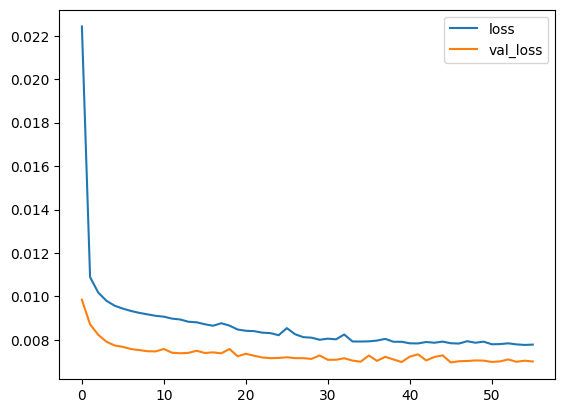

In [7]:
plt.plot(history_low.history['loss'], label='loss')
plt.plot(history_low.history['val_loss'], label='val_loss')

plt.legend()


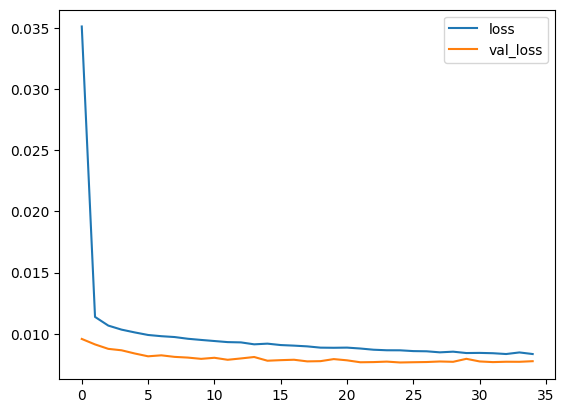

In [8]:
plt.plot(history_high.history['loss'], label='loss')
plt.plot(history_high.history['val_loss'], label='val_loss')

plt.legend()

In [9]:
eagles_output_high = model_high.predict(eagles_x)
eagles_output_low = model_low.predict(eagles_x)

vezhen_output_high = model_high.predict(vezhen_x)
vezhen_output_low = model_low.predict(vezhen_x)

11/11 [==============================] - 0s 1ms/step


0.8793103448275862

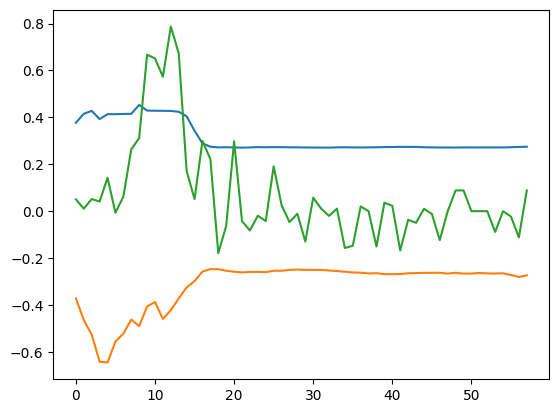

In [28]:
plt.plot(eagles_output_high[:, 0, 0])
plt.plot(eagles_output_low[:, 0, 0])
plt.plot(eagles_y[:, 0, 0])

np.mean(
    (eagles_y[:, :, 0] > eagles_output_low[:, :, 0]) &
    (eagles_y[:, :, 0] < eagles_output_high[:, :, 0])
)

0.8724137931034482

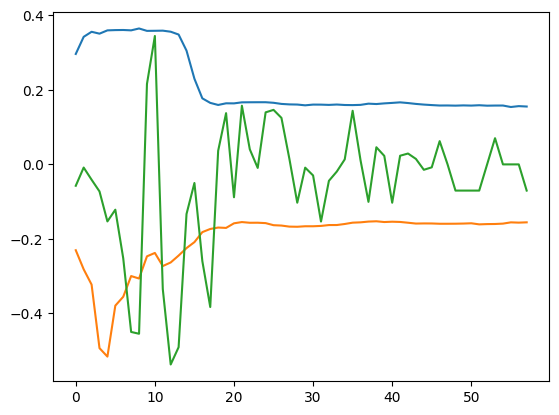

In [29]:
plt.plot(eagles_output_high[:, 0, 1])
plt.plot(eagles_output_low[:, 0, 1])
plt.plot(eagles_y[:, 0, 1])

np.mean(
    (eagles_y[:, :, 1] > eagles_output_low[:, :, 1]) &
    (eagles_y[:, :, 1] < eagles_output_high[:, :, 1])
)

0.8310344827586207

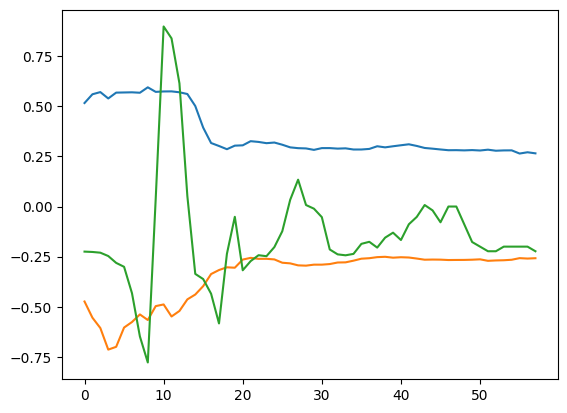

In [30]:
plt.plot(eagles_output_high[:, 0, 2])
plt.plot(eagles_output_low[:, 0, 2])
plt.plot(eagles_y[:, 0, 2])

np.mean(
    (eagles_y[:, :, 2] > eagles_output_low[:, :, 2]) &
    (eagles_y[:, :, 2] < eagles_output_high[:, :, 2])
)

0.9676300578034682

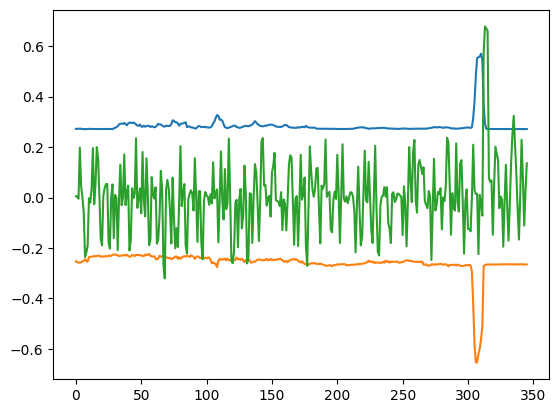

In [13]:
plt.plot(vezhen_output_high[:, 0, 0])
plt.plot(vezhen_output_low[:, 0, 0])
plt.plot(vezhen_y[:, 0, 0])

np.mean(
    (vezhen_y[:, :, 0] > vezhen_output_low[:, :, 0]) &
    (vezhen_y[:, :, 0] < vezhen_output_high[:, :, 0])
)

0.9606936416184971

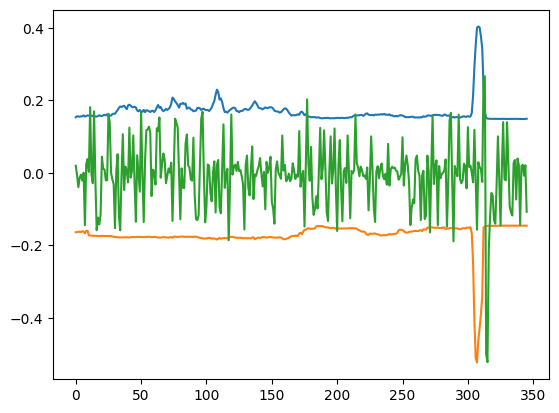

In [14]:
plt.plot(vezhen_output_high[:, 0, 1])
plt.plot(vezhen_output_low[:, 0, 1])
plt.plot(vezhen_y[:, 0, 1])

np.mean(
    (vezhen_y[:, :, 1] > vezhen_output_low[:, :, 1]) &
    (vezhen_y[:, :, 1] < vezhen_output_high[:, :, 1])
)

0.953757225433526

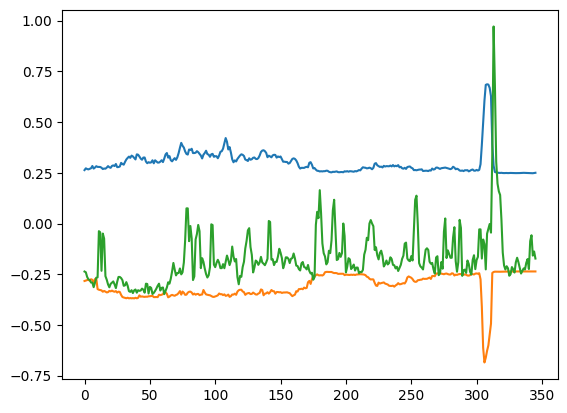

In [15]:
plt.plot(vezhen_output_high[:, 0, 2])
plt.plot(vezhen_output_low[:, 0, 2])
plt.plot(vezhen_y[:, 0, 2])

np.mean(
    (vezhen_y[:, :, 2] > vezhen_output_low[:, :, 2]) &
    (vezhen_y[:, :, 2] < vezhen_output_high[:, :, 2])
)

In [16]:
y_pred = model_low.predict(X_test)

264/264 [==============================] - 0s 1ms/step


In [17]:
from sklearn.metrics import mean_pinball_loss

In [18]:
mean_pinball_loss( y_test[:, 0, 0], y_pred[:, 0, 0], alpha=0.025 )

0.008776662011877077

In [19]:
y_high = model_high.predict(X_test)
y_low = model_low.predict(X_test)

picp_res = np.mean( (y_test < y_high) & (y_test > y_low), axis=0 )
pinaw_res = np.mean( np.abs(y_high - y_low), axis=0 )

loss_low_res = mean_pinball_loss(y_test.reshape((-1, 15)), y_low.reshape((-1,15)), alpha=0.025, multioutput='raw_values')
loss_high_res = mean_pinball_loss(y_test.reshape((-1, 15)), y_high.reshape((-1,15)), alpha=0.975, multioutput='raw_values')

264/264 [==============================] - 0s 1ms/step


In [20]:
import pandas as pd

In [21]:
df_picp = pd.DataFrame(picp_res, columns=['delta_cog', 'delta_dif', 'dif'])
df_picp['time_step'] = list(range(5,30,5))
df_picp

,delta_cog,delta_dif,dif,time_step
0,0.958062,0.972871,0.967421,5
1,0.957943,0.975832,0.967895,10
2,0.959720,0.981282,0.971449,15
3,0.959010,0.980926,0.969672,20
4,0.959365,0.981282,0.965999,25


In [22]:
df_pinaw = pd.DataFrame(pinaw_res, columns=['delta_cog', 'delta_dif', 'dif'])
df_pinaw['time_step'] = list(range(5,30,5))
df_pinaw

,delta_cog,delta_dif,dif,time_step
0,0.548004,0.327858,0.551853,5
1,0.543530,0.332084,0.566736,10
2,0.552638,0.341811,0.579014,15
3,0.551682,0.343391,0.580441,20
4,0.551761,0.344435,0.581104,25


In [23]:
df_loss_low = pd.DataFrame(loss_low_res.reshape((5, 3)), columns=['delta_cog', 'delta_dif', 'dif'])
df_loss_low['time_step'] = list(range(5,30,5))
df_loss_low

,delta_cog,delta_dif,dif,time_step
0,0.008777,0.004348,0.006640,5
1,0.008784,0.004415,0.006721,10
2,0.008812,0.004458,0.006757,15
3,0.008864,0.004512,0.006779,20
4,0.008915,0.004537,0.006824,25


In [24]:
df_loss_high = pd.DataFrame(loss_high_res.reshape((5, 3)), columns=['delta_cog', 'delta_dif', 'dif'])
df_loss_high['time_step'] = list(range(5,30,5))
df_loss_high

,delta_cog,delta_dif,dif,time_step
0,0.008651,0.004487,0.007890,5
1,0.008622,0.004499,0.008226,10
2,0.008625,0.004601,0.008476,15
3,0.008641,0.004621,0.008559,20
4,0.008663,0.004629,0.008613,25


In [25]:
df_picp.to_csv('../../output/data_eagles_vezhen/lstm-ae/picp-lstm.csv')
df_pinaw.to_csv('../../output/data_eagles_vezhen/lstm-ae/pinaw-lstm.csv')
df_loss_low.to_csv('../../output/data_eagles_vezhen/lstm-ae/loss_low-lstm.csv')
df_loss_high.to_csv('../../output/data_eagles_vezhen/lstm-ae/loss_high-lstm.csv')

In [26]:
y_val_low = model_low.predict(X_val)
y_val_high = model_high.predict(X_val)

val_mmsis = np.load('../../output/data_eagles_vezhen2/val-mmsis.npy', allow_pickle=True)
val_days = np.load('../../output/data_eagles_vezhen2/val-days.npy', allow_pickle=True)

in_pi_mask = (y_val > y_val_low) & (y_val < y_val_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

thresh_delta_cog = np.quantile(df['delta_cog'], 0.05)
thresh_delta_dif = np.quantile(df['delta_dif'], 0.05)
thresh_dif = np.quantile(df['dif'], 0.05)

print( 'delta_cog limit:', np.quantile(df['delta_cog'], 0.05) )
print( 'delta_dif liimt:', np.quantile(df['delta_dif'], 0.05) )
print( 'dif liimt:', np.quantile(df['dif'], 0.05) )

243/243 [==============================] - 0s 969us/step
delta_cog limit: 0.7943971631205669
delta_dif liimt: 0.8674999999999997
dif liimt: 0.7000499001996008


In [27]:
in_pi_mask = (y_test > y_low) & (y_test < y_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

test_mmsis = np.load('../../output/data_eagles_vezhen2/test-mmsis.npy', allow_pickle=True)
test_days = np.load('../../output/data_eagles_vezhen2/test-days.npy', allow_pickle=True)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(test_mmsis, test_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

In [30]:
(df['delta_cog'] < thresh_delta_cog).mean()

0.01282051282051282

In [31]:
(df['dif'] < thresh_dif).mean()

0.0

In [32]:
(df['delta_dif'] < thresh_delta_dif).mean()

0.038461538461538464